# Fig. 4 — per-family PQS for all seven models

Draws the 7-panel *Prompt Quality Score by family* figure from the seven `*_per_family.csv` files in `data/per_family/`.

* **Bars are mean PQS:** the per-family mean of the composite PQS, whose components are z-scored within each model. Bars are therefore zero-centred within a model but not unit-variance, and panel x-ranges differ. The dynamic ranges quoted in Section 5.2 (0.28 to 5.61) are read from these values, so they are not re-standardised.
* **One family order on every panel:** the mean rank across the seven models (best at top). Bars that fail to line up against this order are the visual counterpart of the low Kendall's *W*.
* **Independent x-axis per panel**, each annotated with its PQS range (max − min).

**How to run:** in Colab, Runtime → Run all and upload the seven `*_per_family.csv` files when prompted. Locally, set `LOCAL_CSV_DIR` in the CONFIG cell to `data/per_family/`. Outputs: vector `.pdf` and 400-dpi `.png`.

All choices (model order, colours, annotations, output filename) are set in the **CONFIG** cell.

In [1]:
# === Imports =================================================================
import os, sys, io, re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

Running in Colab: True


In [2]:
# === CONFIG (edit here) =====================================================

# Panel order, left-to-right then top-to-bottom. Each entry is:
#   (match_key, display_label)
# `match_key` is matched (case-insensitive, underscores/dashes ignored) against
# each uploaded CSV filename, so you do not have to rename your files. The first
# unique substring match wins; the run prints exactly what matched so you can
# verify before trusting the figure.
MODELS = [
    ("distilgpt2_per_family",            "DistilGPT-2"),
    ("qwen2_5_0_5b_per_family",          "Qwen2.5-0.5B"),
    ("qwen2_5_0_5b_instruct_per_family", "Qwen2.5-0.5B-Instruct"),
    ("qwen2_5_7b_per_family",            "Qwen2.5-7B"),
    ("qwen2_5_7b_instruct_per_family",   "Qwen2.5-7B-Instruct"),
    ("llama_3_1_8b_per_family",          "Llama-3.1-8B"),
    ("llama_3_1_8b_instruct_per_family", "Llama-3.1-8B-Instruct"),
]

# Grid shape. 7 panels -> 4 rows x 2 cols (last cell left blank).
# Portrait, because the Springer sn-jnl single-column measure is only 5.15 in;
# a 2x4 strip would have to be scaled to ~0.36 and the in-figure text would
# print at 3-4 pt. See FIG_W_IN below.
NROWS, NCOLS = 4, 2

# --- Final printed size, in inches. The figure is DRAWN at this size and
# --- included with width=\textwidth, so LaTeX applies NO scaling and every
# --- font below prints at exactly the point size you set.
#     sn-jnl single column: text={31pc, 194.25mm} -> 31pc = 372pt = 5.147 in wide,
#     194.25 mm = 7.65 in tall. 7.0 in leaves room for the caption.
FIG_W_IN = 5.15
FIG_H_IN = 7.00

# Font sizes are TRUE printed sizes now (no scaling). Springer's floor is ~6 pt.
FS_BASE, FS_TITLE, FS_TICK, FS_ANNOT = 8.0, 8.5, 7.0, 6.5

# Column in each CSV that holds the per-family score to plot.
SCORE_COL  = "PQS"
FAMILY_COL = "family"

# Family order applied identically to every panel.
#   "mean_rank"  : mean rank across models (RECOMMENDED; companion to Kendall W)
#   "grand_mean" : by grand mean of the score across models
#   "alpha"      : alphabetical (no cherry-picking, but hides the W story)
#   or pass an explicit list, e.g. ["concise","expert",...], to force an order.
FAMILY_ORDER = "mean_rank"

# Colours: teal = at/above that model's average (score >= 0), red = below.
COLOR_POS = "#2a9d8f"
COLOR_NEG = "#c1666b"
BAR_EDGE  = "black"

# Annotations / labels
ANNOTATE_RANGE   = True    # show "range = X.XX" (max-min PQS) in each panel
PER_BAR_VALUES   = False   # write each bar's value at its tip (busy with 7 panels)
MONO_FAMILY_TICK = True    # monospace family labels, to mirror \texttt{} in the paper

# Titles / labels (kept honest: the plotted quantity is a mean, not a z-score)
# Set SUPTITLE = None and put this text in the LaTeX \caption instead: an
# in-figure title costs ~0.5 in of a 7 in canvas and Springer prefers captions.
SUPTITLE = None
XLABEL   = "Mean PQS"

# Output. Default name avoids the misleading "_shared" tag; if you would rather
# not touch the two \includegraphics lines in the .tex, set this back to
# "pqs_facet_all_shared".
OUTPUT_BASENAME = "pqs_facet_freex"
SAVE_PNG_DPI    = 600

# Where to look for CSVs when NOT uploading (local / non-Colab runs).
LOCAL_CSV_DIR = "."

In [3]:
# === Matplotlib style (sized for the sn-jnl single-column measure) =========
# Because the figure is drawn at its final size, these ARE the printed sizes.
mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": SAVE_PNG_DPI,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,   # embed TrueType, never Type 3
    "font.family": "DejaVu Sans",
    "font.size": FS_BASE,
    "axes.titlesize": FS_TITLE, "axes.titleweight": "bold",
    "axes.labelsize": FS_BASE,
    "xtick.labelsize": FS_TICK, "ytick.labelsize": FS_TICK,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
})


In [4]:
# === Load the seven per-family CSVs =========================================
def _norm(s):
    """Lowercase and strip non-alphanumerics so 'Qwen2.5-7B' ~ 'qwen2_5_7b'."""
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def _match_files(filenames):
    """Map each MODELS entry to exactly one filename by normalised substring.
    Longer keys are matched first so '..._instruct' wins over its base prefix."""
    norm = {fn: _norm(fn) for fn in filenames}
    order = sorted(range(len(MODELS)), key=lambda i: -len(MODELS[i][0]))
    taken, chosen = set(), {}
    for i in order:
        key = _norm(MODELS[i][0])
        hit = next((fn for fn in filenames
                    if fn not in taken and key in norm[fn]), None)
        if hit:
            chosen[i] = hit; taken.add(hit)
    return chosen

# Gather the raw CSV bytes either from a Colab upload or a local directory.
raw = {}
if IN_COLAB:
    from google.colab import files
    print("Upload the seven *_per_family.csv files (multi-select is fine):")
    up = files.upload()
    raw = {name: data for name, data in up.items() if name.lower().endswith(".csv")}
else:
    for fn in sorted(os.listdir(LOCAL_CSV_DIR)):
        if fn.lower().endswith("per_family.csv"):
            with open(os.path.join(LOCAL_CSV_DIR, fn), "rb") as fh:
                raw[fn] = fh.read()

assert raw, "No CSV files found. Upload the seven *_per_family.csv files."

chosen = _match_files(list(raw.keys()))

# Build label -> Series(PQS indexed by family), in the configured panel order.
data, used = {}, set()
print("\nFile -> model mapping:")
for i, (key, label) in enumerate(MODELS):
    fn = chosen.get(i)
    if fn is None:
        print(f"  [MISSING] {label:24s} <- no file matched key '{key}'")
        continue
    df = pd.read_csv(io.BytesIO(raw[fn]))
    assert FAMILY_COL in df and SCORE_COL in df, \
        f"{fn} must contain '{FAMILY_COL}' and '{SCORE_COL}' columns; got {list(df.columns)}"
    df[FAMILY_COL] = df[FAMILY_COL].astype(str).str.strip().str.lower()
    s = df.set_index(FAMILY_COL)[SCORE_COL].astype(float)
    data[label] = s
    used.add(fn); print(f"  {label:24s} <- {fn}")

unused = [fn for fn in raw if fn not in used]
if unused:
    print("\nUnused uploads (ignored):", unused)
assert data, "No CSVs could be matched to the MODELS list -- check filenames/keys."
print(f"\nLoaded {len(data)} models.")

Upload the seven *_per_family.csv files (multi-select is fine):


Saving distilgpt2_per_family.csv to distilgpt2_per_family.csv
Saving llama_3_1_8b_instruct_per_family.csv to llama_3_1_8b_instruct_per_family.csv
Saving llama_3_1_8b_per_family.csv to llama_3_1_8b_per_family.csv
Saving qwen2_5_0_5b_instruct_per_family.csv to qwen2_5_0_5b_instruct_per_family.csv
Saving qwen2_5_0_5b_per_family.csv to qwen2_5_0_5b_per_family.csv
Saving qwen2_5_7b_instruct_per_family.csv to qwen2_5_7b_instruct_per_family.csv
Saving qwen2_5_7b_per_family.csv to qwen2_5_7b_per_family.csv

File -> model mapping:
  DistilGPT-2              <- distilgpt2_per_family.csv
  Qwen2.5-0.5B             <- qwen2_5_0_5b_per_family.csv
  Qwen2.5-0.5B-Instruct    <- qwen2_5_0_5b_instruct_per_family.csv
  Qwen2.5-7B               <- qwen2_5_7b_per_family.csv
  Qwen2.5-7B-Instruct      <- qwen2_5_7b_instruct_per_family.csv
  Llama-3.1-8B             <- llama_3_1_8b_per_family.csv
  Llama-3.1-8B-Instruct    <- llama_3_1_8b_instruct_per_family.csv

Loaded 7 models.


In [5]:
# === Compute the single family order used on every panel ====================
all_families = sorted({f for s in data.values() for f in s.index})

if isinstance(FAMILY_ORDER, (list, tuple)):
    global_order = [f for f in FAMILY_ORDER if f in all_families]
    missing = [f for f in all_families if f not in global_order]
    global_order += missing                      # append any families not listed
    order_desc = "explicit (config list)"
elif FAMILY_ORDER == "alpha":
    global_order = sorted(all_families)
    order_desc = "alphabetical"
elif FAMILY_ORDER == "grand_mean":
    grand = pd.DataFrame(data).mean(axis=1)       # mean score per family across models
    global_order = grand.sort_values(ascending=False).index.tolist()
    order_desc = "grand mean of score across models (best first)"
else:  # "mean_rank" (default)
    # Per model: rank 1 = best (highest score). Average ranks across models.
    ranks = pd.DataFrame({lbl: s.rank(ascending=False) for lbl, s in data.items()})
    mean_rank = ranks.mean(axis=1).sort_values()  # lowest mean rank = best
    global_order = mean_rank.index.tolist()
    order_desc = "mean rank across models (best first; companion to Kendall W)"
    print("Mean rank per family (1 = best):")
    print(mean_rank.round(2).to_string(), "\n")

print("Family order applied to every panel ->", order_desc)
print("  " + "  >  ".join(global_order))

# Sanity table: per-model PQS range (max - min). These should reproduce the
# dynamic-range numbers quoted in Section 5.2 of the paper.
rng = pd.DataFrame({
    "best":  {lbl: s.idxmax() for lbl, s in data.items()},
    "worst": {lbl: s.idxmin() for lbl, s in data.items()},
    "range (max-min)": {lbl: float(s.max() - s.min()) for lbl, s in data.items()},
}).reindex([lbl for _, lbl in MODELS if lbl in data])
print("\nPer-model PQS spread (cross-check vs paper Section 5.2):")
print(rng.round(3).to_string())

Mean rank per family (1 = best):
family
concise            2.43
expert             3.86
robust             4.14
base               4.57
formatting         4.71
structured         5.00
cot                5.57
overconstrained    5.71 

Family order applied to every panel -> mean rank across models (best first; companion to Kendall W)
  concise  >  expert  >  robust  >  base  >  formatting  >  structured  >  cot  >  overconstrained

Per-model PQS spread (cross-check vs paper Section 5.2):
                             best            worst  range (max-min)
DistilGPT-2                expert  overconstrained            0.278
Qwen2.5-0.5B              concise             base            3.498
Qwen2.5-0.5B-Instruct     concise              cot            3.374
Qwen2.5-7B                 expert             base            1.514
Qwen2.5-7B-Instruct       concise       structured            4.162
Llama-3.1-8B           structured  overconstrained            0.918
Llama-3.1-8B-Instruct     concise

Saved: pqs_facet_freex.png and pqs_facet_freex.pdf
Canvas: 5.15 x 7.00 in  (sn-jnl 1-col target 5.15 x <=7.65)
Smallest text on the page: 6.5 pt (Springer floor ~6 pt)


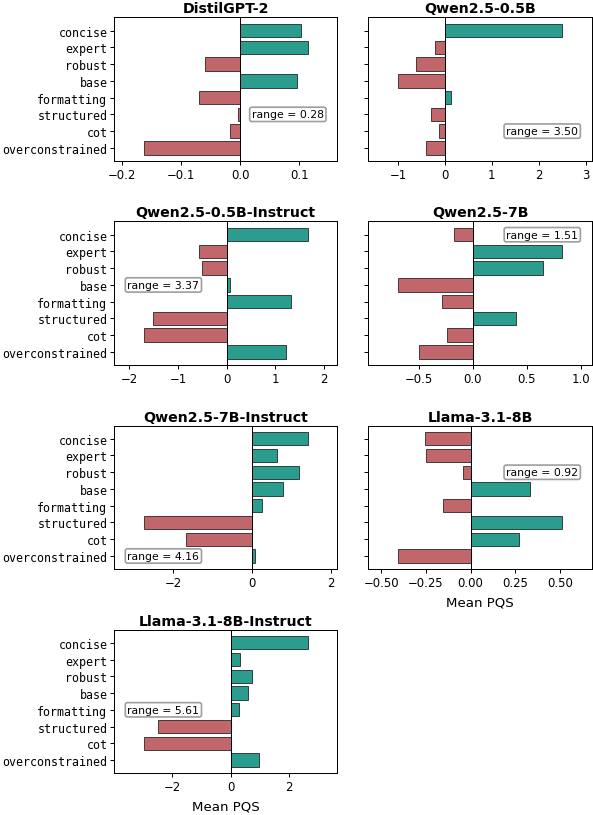

In [6]:
# === Build the facet figure =================================================
labels_in_order = [lbl for _, lbl in MODELS if lbl in data]
n = len(labels_in_order)

# Drawn at final printed size -- do NOT let LaTeX scale this.
fig, axes = plt.subplots(NROWS, NCOLS, figsize=(FIG_W_IN, FIG_H_IN))
axes = np.atleast_1d(axes).ravel()

y = np.arange(len(global_order))[::-1]          # first family in global_order -> top
tickfont = {"family": "monospace"} if MONO_FAMILY_TICK else {}

for k, label in enumerate(labels_in_order):
    ax = axes[k]
    s = data[label].reindex(global_order)        # same order on every panel
    vals = s.values
    colors = [COLOR_POS if (v is not None and not np.isnan(v) and v >= 0)
              else COLOR_NEG for v in vals]

    ax.barh(y, np.nan_to_num(vals), color=colors,
            edgecolor=BAR_EDGE, linewidth=0.4)
    ax.axvline(0, color="black", lw=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(global_order, fontdict=tickfont)
    ax.set_title(label, pad=3)
    ax.margins(x=0.18)
    ax.tick_params(axis="x", pad=1.5)
    ax.tick_params(axis="y", pad=1.5)
    ax.locator_params(axis="x", nbins=5)

    # Family names only on the left column; x-label only on the lowest
    # occupied panel of each column. Saves ~1.2 in of vertical space.
    if k % NCOLS != 0:
        ax.set_yticklabels([])
    if k >= n - NCOLS:
        ax.set_xlabel(XLABEL)
    else:
        ax.set_xlabel("")

    if PER_BAR_VALUES:
        for yi, v in zip(y, vals):
            if v is None or np.isnan(v):
                continue
            ax.text(v + (0.01 if v >= 0 else -0.01), yi, f"{v:+.2f}",
                    va="center", ha="left" if v >= 0 else "right",
                    fontsize=6.5, fontweight="bold")

    if ANNOTATE_RANGE and np.isfinite(vals).any():
        rng_val = float(np.nanmax(vals) - np.nanmin(vals))
        # Anchor to the row with the SMALLEST |value| (most empty space around
        # it), on whichever side of x=0 that row's bar does NOT occupy. A fixed
        # bottom-right corner (the previous approach) collides with the bottom
        # bar whenever that family happens to score high for a given model --
        # exactly what happened for Qwen2.5-0.5B-Instruct and
        # Llama-3.1-8B-Instruct once real data was plotted.
        finite_idx = np.where(np.isfinite(vals))[0]
        row = finite_idx[np.argmin(np.abs(vals[finite_idx]))]
        bar_val = vals[row]
        xlo, xhi = ax.get_xlim()
        if bar_val >= 0:
            xpos, ha = xlo + 0.06 * (xhi - xlo), "left"
        else:
            xpos, ha = xhi - 0.06 * (xhi - xlo), "right"
        ax.text(xpos, y[row], f"range = {rng_val:.2f}",
                ha=ha, va="center", fontsize=FS_ANNOT,
                bbox=dict(boxstyle="round,pad=0.2", fc="white",
                          ec="0.6", alpha=0.95), zorder=5)

# Hide any leftover empty panels (e.g. the 8th cell in a 2x4 grid).
for j in range(n, len(axes)):
    axes[j].axis("off")

if SUPTITLE:
    fig.suptitle(SUPTITLE, fontsize=FS_TITLE + 1.5, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
else:
    fig.tight_layout()
fig.subplots_adjust(wspace=0.14, hspace=0.42)

png_path = OUTPUT_BASENAME + ".png"
pdf_path = OUTPUT_BASENAME + ".pdf"
fig.savefig(png_path, dpi=SAVE_PNG_DPI)          # backup only, not for submission
fig.savefig(pdf_path, format="pdf")              # vector, this is the deliverable
print("Saved:", png_path, "and", pdf_path)

# --- Preflight: fail loudly if anything got rasterised or a Type 3 crept in.
w_in, h_in = fig.get_size_inches()
print(f"Canvas: {w_in:.2f} x {h_in:.2f} in  (sn-jnl 1-col target 5.15 x <=7.65)")
assert w_in <= 5.20, "Wider than the sn-jnl single-column measure -- it will be scaled."
print("Smallest text on the page:", min(FS_BASE, FS_TICK, FS_ANNOT), "pt (Springer floor ~6 pt)")
plt.show()

In [7]:
# === Download + ready-to-paste LaTeX ========================================
if IN_COLAB:
    from google.colab import files
    files.download(pdf_path)
    files.download(png_path)

print("\n--- Replace the figure block in information_geometry_final.tex with: ---\n")
print(r"\begin{figure}[t]")   # sn-jnl does not use the cas-sc [pos=..] key
print(r"\centering")
print(r"\includegraphics[width=\textwidth]{%s}" % pdf_path)
print(r"\caption{Prompt Quality Score by family, per model. Bars are the")
print(r"  mean PQS (Eq.~\ref{eq:pqs}); the six PQS \emph{components} are")
print(r"  $z$-standardised within each model, so the bars are centred at zero")
print(r"  within a model but are not unit-variance. Families appear in the same")
print(r"  order in every panel (mean rank across the seven models, best at top),")
print(r"  so a family whose bar jumps between panels signals cross-model")
print(r"  disagreement in ranking. The $x$-axis is independent per panel; each")
print(r"  panel is annotated with its PQS range (max$-$min). Teal bars are")
print(r"  at or above a model's average, red below.}")
print(r"\label{fig:pqs}")
print(r"\end{figure}")
print("\nAlso update the body sentence so it no longer says the panels are")
print('"z-scored within each model" -- say the PQS *components* are z-scored.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


--- Replace the figure block in information_geometry_final.tex with: ---

\begin{figure}[t]
\centering
\includegraphics[width=\textwidth]{pqs_facet_freex.pdf}
\caption{Prompt Quality Score by family, per model. Bars are the
  mean PQS (Eq.~\ref{eq:pqs}); the six PQS \emph{components} are
  $z$-standardised within each model, so the bars are centred at zero
  within a model but are not unit-variance. Families appear in the same
  order in every panel (mean rank across the seven models, best at top),
  so a family whose bar jumps between panels signals cross-model
  disagreement in ranking. The $x$-axis is independent per panel; each
  panel is annotated with its PQS range (max$-$min). Teal bars are
  at or above a model's average, red below.}
\label{fig:pqs}
\end{figure}

Also update the body sentence so it no longer says the panels are
"z-scored within each model" -- say the PQS *components* are z-scored.
